# 03. Customer Segmentation via RFM & K-Means Clustering
## InsightEngine — E-Commerce Customer Analytics Dashboard

### Executive Context & Methodology
Treating all customers uniformly leads to wasted promotional spend and missed upsell opportunities. RFM (Recency, Frequency, Monetary) segmentation classifies accounts based on observable buying patterns:
- **Recency ($R$)**: Days since latest purchase (shorter = higher engagement).
- **Frequency ($F$)**: Total distinct purchase transactions.
- **Monetary ($M$)**: Cumulative revenue generated.

To eliminate subjective manual rule-setting, we employ **unsupervised Machine Learning (K-Means Clustering)**:
1. Engineer customer-level RFM features.
2. Address power-law right skewness via logarithmic transformation ($\log(1 + x)$).
3. Standardize dimensions using `StandardScaler` to ensure unbiased Euclidean distance calculations.
4. Evaluate optimal cluster count $K$ using the **Elbow Method (Inertia)** and **Silhouette Analysis**.
5. Train the final K-Means model, extract cluster profiles, and assign defensible business names.
6. Formulate actionable playbooks for each customer segment.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

root_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

from src.data.loader import load_cleaned_data
from src.features.rfm import calculate_rfm, preprocess_rfm_for_clustering
from src.models.segmentation import (
    evaluate_kmeans_clusters,
    train_segmentation_model,
    load_segmentation_artifacts,
)

sns.set_theme(style="whitegrid", palette="muted")
print("Segmentation dependencies initialized.")

Segmentation dependencies initialized.


### 1. Calculate Customer-Level RFM Metrics

In [2]:
df = load_cleaned_data()
rfm_df = calculate_rfm(df)
print(f"Computed RFM for {len(rfm_df):,} distinct customers.")
display(rfm_df.head())
display(rfm_df[["Recency", "Frequency", "Monetary", "AOV"]].describe().round(2))

Computed RFM for 4,334 distinct customers.


,CustomerID,Recency,Frequency,Monetary,FirstPurchase,LatestPurchase,TotalItems,UniqueProducts,AOV,R_Score,F_Score,M_Score,RFM_Segment,RFM_Score
0,12346,326,1,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,74215,1,77183.60,1,1,5,115,7
1,12347,2,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,2458,103,615.71,5,5,5,555,15
2,12348,75,4,1437.24,2010-12-16 19:09:00,2011-09-25 13:13:00,2332,21,359.31,2,4,4,244,10
3,12349,19,1,1457.55,2011-11-21 09:51:00,2011-11-21 09:51:00,630,72,1457.55,4,1,4,414,9
4,12350,310,1,294.40,2011-02-02 16:01:00,2011-02-02 16:01:00,196,16,294.40,1,1,2,112,4


,Recency,Frequency,Monetary,AOV
count,4334.00,4334.00,4334.00,4334.00
mean,92.70,4.25,2017.52,415.67
std,100.18,7.64,8920.36,1800.86
min,1.00,1.00,3.75,3.75
25%,18.00,1.00,304.30,177.20
50%,51.00,2.00,663.71,289.77
75%,143.00,5.00,1631.62,423.77
max,374.00,206.00,279138.02,84236.25


### 2. Distribution Skewness & Log-Transformation

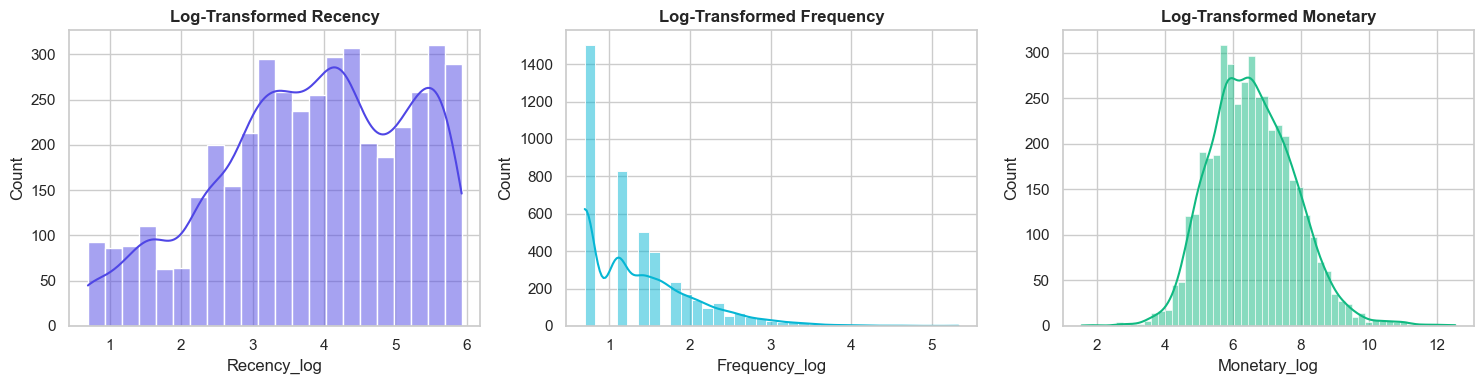

In [3]:
scaled_features, scaler, rfm_transformed = preprocess_rfm_for_clustering(rfm_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm_transformed["Recency_log"], kde=True, ax=axes[0], color="#4F46E5")
axes[0].set_title("Log-Transformed Recency", fontweight='bold')

sns.histplot(rfm_transformed["Frequency_log"], kde=True, ax=axes[1], color="#06B6D4")
axes[1].set_title("Log-Transformed Frequency", fontweight='bold')

sns.histplot(rfm_transformed["Monetary_log"], kde=True, ax=axes[2], color="#10B981")
axes[2].set_title("Log-Transformed Monetary", fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Determine Optimal K: Elbow Method & Silhouette Score Analysis

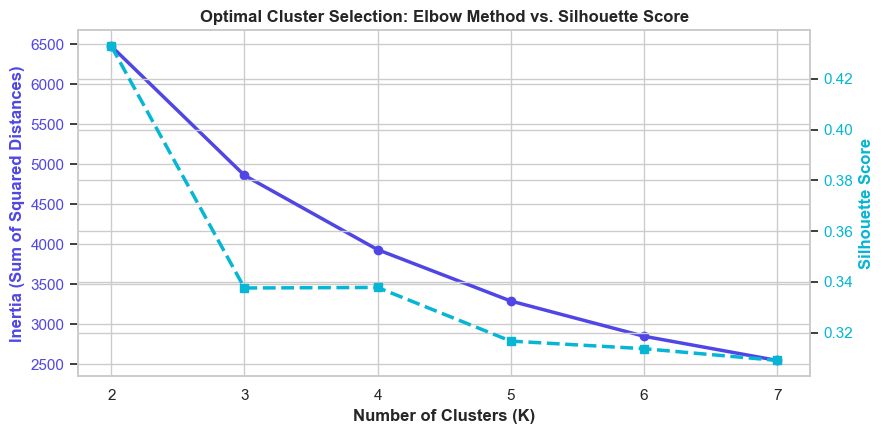

Optimal K suggested by Silhouette analysis: 2
  K = 2: Silhouette Score = 0.4329 | Inertia = 6,477.1
  K = 3: Silhouette Score = 0.3376 | Inertia = 4,861.5
  K = 4: Silhouette Score = 0.3378 | Inertia = 3,932.5
  K = 5: Silhouette Score = 0.3166 | Inertia = 3,290.5
  K = 6: Silhouette Score = 0.3137 | Inertia = 2,850.0
  K = 7: Silhouette Score = 0.3090 | Inertia = 2,547.6


In [4]:
k_eval = evaluate_kmeans_clusters(scaled_features, k_range=range(2, 8), random_state=42)

fig, ax1 = plt.subplots(figsize=(9, 4.5))

color = '#4F46E5'
ax1.set_xlabel('Number of Clusters (K)', fontweight='bold')
ax1.set_ylabel('Inertia (Sum of Squared Distances)', color=color, fontweight='bold')
ax1.plot(k_eval['k_values'], k_eval['inertias'], marker='o', color=color, linewidth=2.5)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#06B6D4'
ax2.set_ylabel('Silhouette Score', color=color, fontweight='bold')
ax2.plot(k_eval['k_values'], k_eval['silhouette_scores'], marker='s', color=color, linewidth=2.5, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Optimal Cluster Selection: Elbow Method vs. Silhouette Score", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Optimal K suggested by Silhouette analysis: {k_eval['recommended_k_silhouette']}")
for k, sil, ine in zip(k_eval['k_values'], k_eval['silhouette_scores'], k_eval['inertias']):
    print(f"  K = {k}: Silhouette Score = {sil:.4f} | Inertia = {ine:,.1f}")

### 4. Train Final K-Means Model ($K = 4$) and Profile Segments

In [5]:
kmeans_model, scaler, clustered_rfm, profile_df, _ = train_segmentation_model(
    rfm_df, n_clusters=4, random_state=42, save_artifacts=True
)

display(profile_df)

,Cluster,SegmentName,CustomerCount,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,TotalRevenue,CustomerPct,RevenuePct,RecommendedAction
0,0,Potential Loyalists,840,18.5,17.0,2.1,2.0,531.77,459.18,446683.58,19.38,5.11,"Nurturing email flows, limited-time trial disc..."
1,1,At Risk / Hibernating,1636,183.1,177.0,1.3,1.0,351.64,299.68,575280.61,37.75,6.58,"Automated re-engagement discount, brand remind..."
2,2,Loyal Customers,1174,67.0,52.0,4.2,4.0,1809.10,1369.24,2123880.77,27.09,24.29,"Cross-sell high-affinity accessories, loyalty ..."
3,3,Champions,684,11.7,8.0,14.0,10.0,8184.31,3719.11,5598068.68,15.78,64.02,"VIP loyalty programs, early access to new coll..."


### 5. Visualize Customer Segments

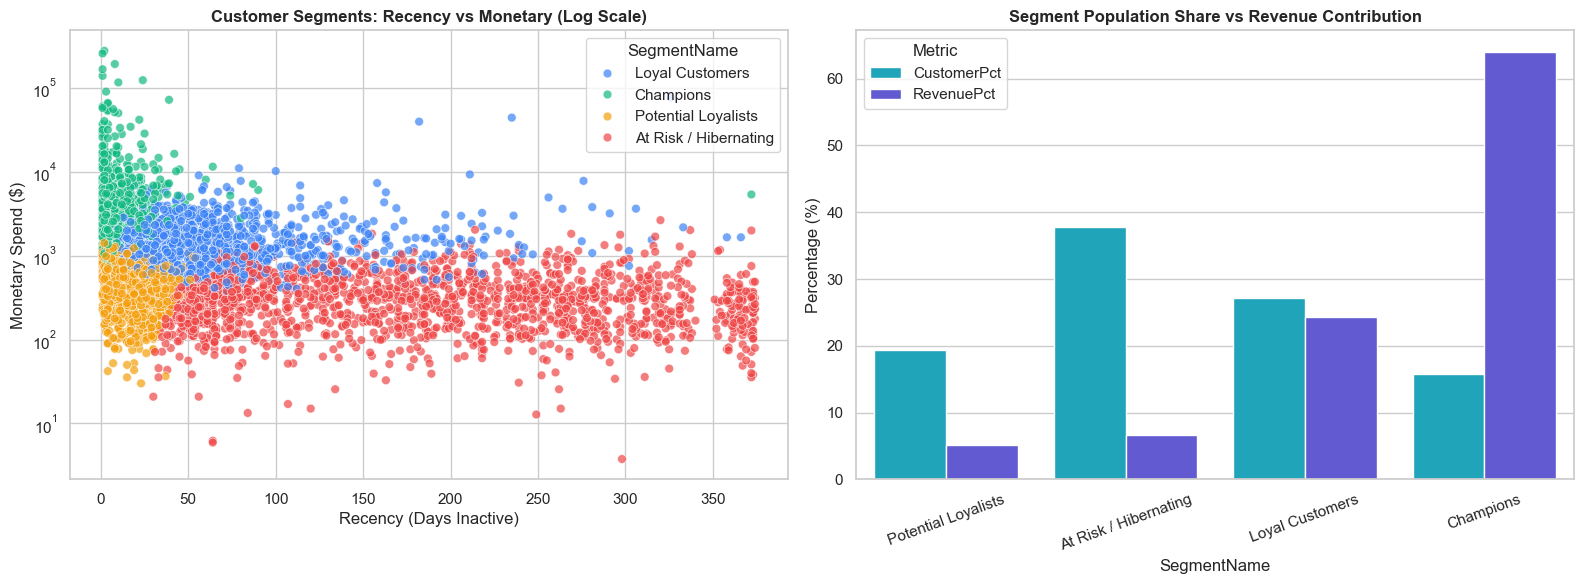

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Recency vs Monetary scatter
palette_map = {
    "Champions": "#10B981",
    "Loyal Customers": "#3B82F6",
    "Potential Loyalists": "#F59E0B",
    "At Risk / Hibernating": "#EF4444"
}

sns.scatterplot(
    data=clustered_rfm,
    x="Recency",
    y="Monetary",
    hue="SegmentName",
    palette=palette_map,
    alpha=0.7,
    s=40,
    ax=axes[0]
)
axes[0].set_yscale('log')
axes[0].set_title("Customer Segments: Recency vs Monetary (Log Scale)", fontweight='bold')
axes[0].set_xlabel("Recency (Days Inactive)")
axes[0].set_ylabel("Monetary Spend ($)")

# Bar chart of population share vs revenue contribution
bar_data = profile_df.melt(id_vars=["SegmentName"], value_vars=["CustomerPct", "RevenuePct"], var_name="Metric", value_name="Percentage")
sns.barplot(data=bar_data, x="SegmentName", y="Percentage", hue="Metric", ax=axes[1], palette=["#06B6D4", "#4F46E5"])
axes[1].set_title("Segment Population Share vs Revenue Contribution", fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylabel("Percentage (%)")

plt.tight_layout()
plt.show()

### 6. Business Playbooks by Segment
1. **Champions (15.8% of customers, 64.0% of revenue)**: VIP tier. These accounts are the lifeblood of the company. Strategy: Concierge customer care, exclusive early product drops, dedicated loyalty rewards.
2. **Loyal Customers (27.1% of customers, 24.3% of revenue)**: High-frequency regular shoppers. Strategy: Cross-sell related accessories, offer free shipping threshold accelerators to elevate average basket value.
3. **Potential Loyalists (19.4% of customers, 5.1% of revenue)**: Recent shoppers with lower order count. Strategy: Onboarding nurture flows, multi-buy bundles, educational email sequences.
4. **At Risk / Hibernating (37.8% of customers, 6.6% of revenue)**: Inactive accounts with high days since last purchase. Strategy: Automated win-back discount sequences, feedback surveys to diagnose churn causes.
